<a href="https://colab.research.google.com/github/KosarZarean/spurious-correlations-colormnist-waterbirds/blob/main/colored_mnist_10colors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colored MNIST با ۱۰ رنگ: اختصاص یک رنگ به هر رقم

**ایده:** در نسخه اصلی رنگ فقط نیمه کلاس (۰–۴ یا ۵–۹) را مشخص می‌کرد، یعنی یک بیت اطلاعات. این‌جا **هر رقم رنگ مخصوص خودش را دارد** (۱۰ رنگ)؛ پس رنگ به‌تنهایی کل برچسب را مشخص می‌کند و میان‌بر بسیار قوی‌تر است.

**ساخت داده:** با احتمال ρ رنگ، همان رنگ رقم است؛ در غیر این صورت رنگ یکی از ۹ رقم دیگر (یکنواخت) است.
- آموزش، اعتبارسنجی و تست ID: ρ = 0.9 (قابل تغییر با `RHO_TRAIN`)
- OOD-1: ρ = 0.1، یعنی رنگ مستقل از رقم (در حد شانس)
- OOD-2: ρ = 0.0، یعنی رنگ همیشه مربوط به یک رقم دیگر است (معکوس کامل)

**تفاوت‌های ارزیابی (چون «نیمه‌کلاس» دیگر معنا ندارد):**
- «نرخ پیروی از رنگ» = درصد پیش‌بینی‌هایی که برابر رقمِ متناظر با رنگ نمایش‌داده‌شده‌اند (سطح شانس ۱۰٪).
- تست A: رنگ هر رقم به رنگ رقم بعدی جابه‌جا می‌شود (c ← c+1).
- تست B (Grayscale با میانگین کانال‌ها) حذف شد، چون رنگ‌ها تعداد کانال روشن متفاوت دارند و میانگین‌گیری شدت را رنگ‌وابسته می‌کند؛ فقط نسخه حفظ‌کننده شدت (رقم سفید) استفاده می‌شود.
- گروه‌های Group DRO: ۲۰ گروه (هر رقم × هم‌جهت/مخالف). Reweighting: وزن = 1/P(رنگ | رقم) با نمونه‌گیری وزن‌دار. Augmentation: ۱۰٪ نمونه با رنگ مستقل (ρ=0.1). IRM: محیط‌ها با ρ=0.9 و ρ=0.5.

**انتظار واقع‌بینانه:** چون رنگ در آموزش ۹۰٪ مواقع برچسب را کامل می‌دهد، انتظار می‌رود وابستگی به رنگ بسیار بیشتر از نسخه دورنگ باشد. اما اندازه افت از پیش معلوم نیست و هر عددی که اجرا بدهد همان گزارش می‌شود. این نوت‌بوک سلول گزارش خودکار ندارد؛ بعد از اجرا `results.json` را بفرستید تا گزارش را از روی اعداد واقعی بنویسم. در گزارش، این را یک **آزمایش تکمیلی با طراحی جدید داده** کنار آزمایش‌های قبلی بیاورید.

**اجرا:** Colab، Runtime → GPU، Run all (حدود ۴۰ تا ۶۰ دقیقه؛ `QUICK_TEST = True` برای تست سریع).

In [1]:
import os, json, time, math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt
import pandas as pd

# ---------------- تنظیمات کلی ----------------
QUICK_TEST = False          # True → تست سریع (۲ epoch، یک seed) فقط برای اطمینان از اجرای بدون خطا
SEEDS      = [0] if QUICK_TEST else [0, 1, 2]
EPOCHS     = 2 if QUICK_TEST else 20
RHO_TRAIN  = 0.9          # احتمال هم‌جهت‌بودن رنگ با رقم در آموزش/اعتبارسنجی/تست ID
OOD1_RHO   = 0.1          # OOD-1: رنگ مستقل از رقم (احتمال هم‌جهت‌بودن = شانس = 0.1)
OOD2_RHO   = 0.0          # OOD-2: رنگ همیشه مخالف رقم (رنگ یک رقم دیگر)
BATCH      = 64
LR         = 1e-3

# هایپرپارامترهای روش‌های کاهش سوگیری (از پیش تعیین شده؛ روی داده OOD تنظیم نشده‌اند)
AUG_FRAC    = 0.10          # روش ۱: نسبت نمونه‌های بدون سوگیری اضافه‌شده (ρ=0.5)
DRO_ETA     = 0.01          # روش ۳: نرخ به‌روزرسانی وزن گروه‌ها (η_q)
GCE_Q       = 0.7           # روش ۴: پارامتر q در Generalized Cross Entropy
EMA_ALPHA   = 0.7           # روش ۴: ضریب EMA برای خطای هر نمونه
IRM_LAMBDA  = 1e4           # روش ۵: وزن جریمه IRM بعد از دوره گرم‌کردن
IRM_ANNEAL  = 1 if QUICK_TEST else 5   # روش ۵: تعداد epochهای اولیه با λ=1

OUT = "results_10colors"
os.makedirs(OUT, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

device: cuda | torch 2.11.0+cu130


## ۱. ساخت داده ۱۰ رنگ

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 499kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 17.0MB/s]


set         N  fraction(color == digit's color)
train   50000  0.900
val     10000  0.896
id      10000  0.899
ood1    10000  0.102
ood2    10000  0.000


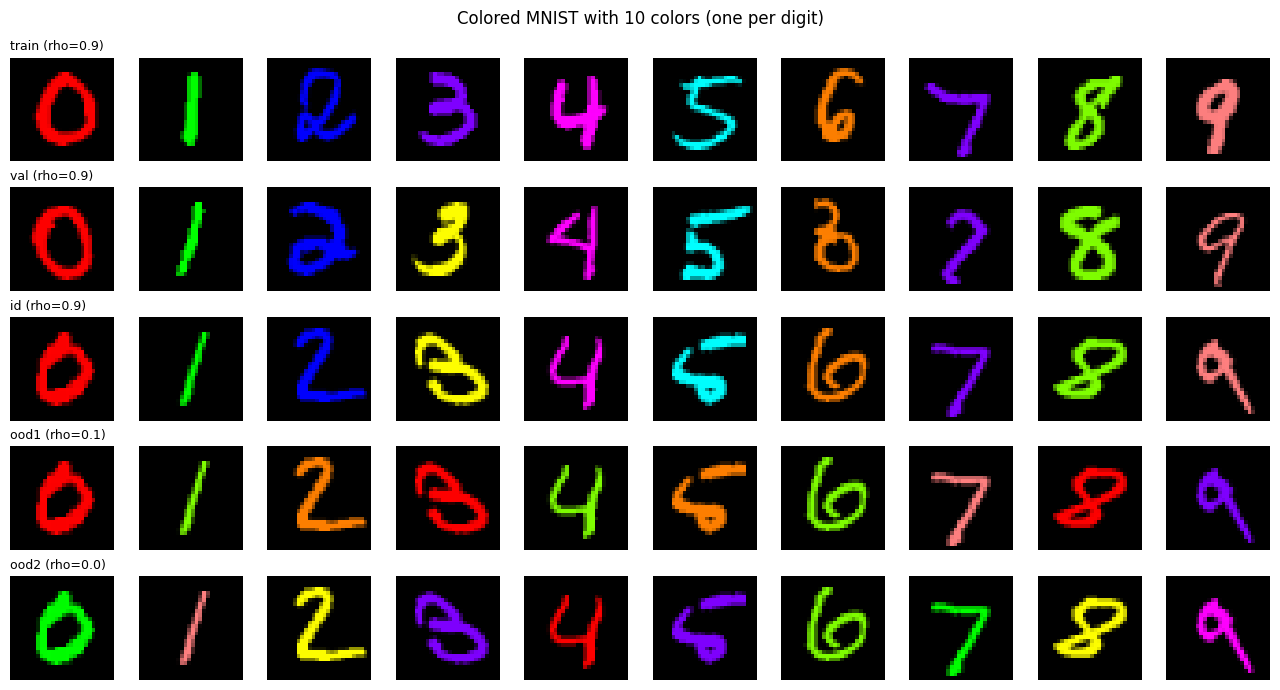

In [2]:
# ---------------- ساخت Colored MNIST با ۱۰ رنگ (هر رقم یک رنگ) ----------------
mn_tr = datasets.MNIST('./data', train=True,  download=True)
mn_te = datasets.MNIST('./data', train=False, download=True)
G_tr = mn_tr.data.numpy().astype(np.float32) / 255.0
Y_tr = mn_tr.targets.numpy().astype(np.int64)
G_te = mn_te.data.numpy().astype(np.float32) / 255.0
Y_te = mn_te.targets.numpy().astype(np.int64)

# ۱۰ رنگ متمایز؛ بیشینه هر رنگ = 1 تا بتوان «رقم خاکستری» را با amax کانال‌ها بازیابی کرد
PALETTE = np.array([[1,0,0],[0,1,0],[0,0,1],[1,1,0],[1,0,1],[0,1,1],[1,.5,0],[.5,0,1],[.5,1,0],[1,.5,.5]], np.float32)
PAL_T = torch.from_numpy(PALETTE).to(DEVICE)

def make_colors(y, rho, seed):
    """رنگ هر نمونه (اندیس 0..9): با احتمال rho رنگِ خود رقم، وگرنه رنگ یکی از ۹ رقم دیگر (یکنواخت)."""
    rng   = np.random.RandomState(seed)
    keep  = rng.rand(len(y)) < rho
    wrong = (y + rng.randint(1, 10, len(y))) % 10
    return np.where(keep, y, wrong)

class CData:
    """مجموعه داده روی GPU. c: اندیس رنگ، aligned: رنگ = رنگ خود رقم، g: گروه = (رقم، هم‌جهت/مخالف) → ۲۰ گروه."""
    def __init__(self, gray, y, color):
        rgb = gray[:, None, :, :] * PALETTE[color][:, :, None, None]       # (N,3,28,28)
        self.x    = torch.from_numpy(rgb.astype(np.float32)).to(DEVICE)
        self.gray = torch.from_numpy(gray).to(DEVICE)
        self.y    = torch.from_numpy(y).long().to(DEVICE)
        self.c    = torch.from_numpy(color).long().to(DEVICE)
        self.aligned = (self.c == self.y)
        self.g    = self.y * 2 + (~self.aligned).long()
    def __len__(self):
        return len(self.y)

def make_cmnist(gray, y, rho, seed):
    return CData(gray, y, make_colors(y, rho, seed))

perm   = np.random.RandomState(42).permutation(len(G_tr))
tr_idx, va_idx = perm[:50000], perm[50000:]
S = {
    'train': make_cmnist(G_tr[tr_idx], Y_tr[tr_idx], RHO_TRAIN, 42),
    'val':   make_cmnist(G_tr[va_idx], Y_tr[va_idx], RHO_TRAIN, 43),
    'id':    make_cmnist(G_te, Y_te, RHO_TRAIN, 44),
    'ood1':  make_cmnist(G_te, Y_te, OOD1_RHO, 45),
    'ood2':  make_cmnist(G_te, Y_te, OOD2_RHO, 46),
}
assert len(set(tr_idx) & set(va_idx)) == 0
SET_INFO = {'train': ('آموزش', RHO_TRAIN), 'val': ('اعتبارسنجی', RHO_TRAIN), 'id': ('تست ID', RHO_TRAIN),
            'ood1': ('تست OOD-1 (رنگ مستقل از رقم)', OOD1_RHO), 'ood2': ('تست OOD-2 (رنگ همیشه مخالف)', OOD2_RHO)}
print(f"{'set':6s} {'N':>6s}  fraction(color == digit's color)")
for k, d in S.items():
    print(f"{k:6s} {len(d):6d}  {d.aligned.float().mean().item():.3f}")

fig, axes = plt.subplots(5, 10, figsize=(13, 7))
for r, (k, d) in enumerate(S.items()):
    for j in range(10):
        i = torch.nonzero(d.y == j)[0, 0].item()
        axes[r, j].imshow(d.x[i].permute(1, 2, 0).cpu().numpy()); axes[r, j].axis('off')
    axes[r, 0].set_title(f"{k} (rho={SET_INFO[k][1]})", loc='left', fontsize=9)
plt.suptitle("Colored MNIST with 10 colors (one per digit)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig0_dataset_samples.png", dpi=150); plt.show()

## ۲. مدل (CNN سه‌لایه اصلی) و ابزارها

In [3]:
# ---------------- مدل و ابزارهای ارزیابی ----------------
class SimpleCNN(nn.Module):
    """همان معماری پیشنهادی صورت پروژه؛ فقط forward به دو بخش features/head تقسیم شده (برای Grad-CAM)."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(128 * 3 * 3, 256)
        self.fc2   = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)
    def features(self, x):                      # خروجی آخرین لایه کانولوشن (بعد از ReLU): 128×7×7
        x = self.pool(F.relu(self.conv1(x)))    # 14x14
        x = self.pool(F.relu(self.conv2(x)))    # 7x7
        return F.relu(self.conv3(x))
    def head(self, f):
        x = self.pool(f)                        # 3x3
        x = x.reshape(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)
    def forward(self, x):
        return self.head(self.features(x))

@torch.no_grad()
def predict(model, x, bs=5000):
    model.eval()
    return torch.cat([model(x[i:i+bs]).argmax(1) for i in range(0, len(x), bs)])

@torch.no_grad()
def eval_loss_acc(model, d, bs=5000):
    model.eval(); L, C = 0.0, 0
    for i in range(0, len(d), bs):
        lo, y = model(d.x[i:i+bs]), d.y[i:i+bs]
        L += F.cross_entropy(lo, y, reduction='sum').item()
        C += (lo.argmax(1) == y).sum().item()
    return L / len(d), C / len(d)

def new_hist():
    return {k: [] for k in ['obj', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'ood1_acc', 'ood2_acc']}

def log_epoch(h, model, obj, tag, ep):
    """ثبت منحنی‌ها روی مجموعه آموزش استاندارد (ρ=0.9) و اعتبارسنجی.
    دقت OOD فقط برای رسم پویایی یادگیری ثبت می‌شود و هرگز برای انتخاب مدل/هایپرپارامتر استفاده نمی‌شود."""
    tl, ta = eval_loss_acc(model, S['train']); vl, va = eval_loss_acc(model, S['val'])
    h['obj'].append(float(obj)); h['train_loss'].append(tl); h['train_acc'].append(ta)
    h['val_loss'].append(vl);    h['val_acc'].append(va)
    h['ood1_acc'].append(eval_loss_acc(model, S['ood1'])[1])
    h['ood2_acc'].append(eval_loss_acc(model, S['ood2'])[1])
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"  [{tag}] epoch {ep+1:2d}  obj={obj:.4f}  train_acc={ta:.4f}  val_acc={va:.4f}  "
              f"ood1={h['ood1_acc'][-1]:.4f}  ood2={h['ood2_acc'][-1]:.4f}")

def final_metrics(model):
    m = {k: eval_loss_acc(model, S[k])[1] for k in ['train', 'val', 'id', 'ood1', 'ood2']}
    d = S['id']; ok = (predict(model, d.x) == d.y)
    m['id_aligned']  = ok[d.aligned].float().mean().item()     # رنگ هم‌جهت با شکل
    m['id_conflict'] = ok[~d.aligned].float().mean().item()    # رنگ مخالف شکل
    return m

RES, HIST, MODELS, CUE = {}, {}, {}, {}     # نتایج: RES[method][seed] ...

def register(method, seed, model, hist):
    RES.setdefault(method, {})[seed]   = final_metrics(model)
    HIST.setdefault(method, {})[seed]  = hist
    MODELS.setdefault(method, {})[seed] = model
    r = RES[method][seed]
    print(f"==> {method} seed={seed}: ID={r['id']:.4f} OOD1={r['ood1']:.4f} OOD2={r['ood2']:.4f}")

def save_results():
    cfg = dict(EPOCHS=EPOCHS, BATCH=BATCH, LR=LR, SEEDS=SEEDS, AUG_FRAC=AUG_FRAC, DRO_ETA=DRO_ETA,
               GCE_Q=GCE_Q, EMA_ALPHA=EMA_ALPHA, IRM_LAMBDA=IRM_LAMBDA, IRM_ANNEAL=IRM_ANNEAL, RHO_TRAIN=RHO_TRAIN, OOD1_RHO=OOD1_RHO, OOD2_RHO=OOD2_RHO, N_COLORS=10,
               N_TRAIN=len(S['train']), DEVICE=DEVICE, QUICK_TEST=QUICK_TEST)
    with open(f"{OUT}/results.json", "w", encoding="utf-8") as f:
        json.dump(dict(cfg=cfg, RES=RES, CUE=CUE, HIST=HIST), f, ensure_ascii=False)

## وظیفه ۱: آموزش مدل پایه

  [Baseline] epoch  1  obj=0.2593  train_acc=0.9859  val_acc=0.9837  ood1=0.9061  ood2=0.8979
  [Baseline] epoch  5  obj=0.0248  train_acc=0.9966  val_acc=0.9924  ood1=0.9642  ood2=0.9611
  [Baseline] epoch 10  obj=0.0112  train_acc=0.9983  val_acc=0.9945  ood1=0.9750  ood2=0.9719
  [Baseline] epoch 15  obj=0.0062  train_acc=0.9994  val_acc=0.9940  ood1=0.9786  ood2=0.9773
  [Baseline] epoch 20  obj=0.0065  train_acc=0.9997  val_acc=0.9949  ood1=0.9774  ood2=0.9758
==> Baseline seed=0: ID=0.9963 OOD1=0.9774 OOD2=0.9758
  [Baseline] epoch  1  obj=0.2507  train_acc=0.9849  val_acc=0.9840  ood1=0.9081  ood2=0.8966
  [Baseline] epoch  5  obj=0.0254  train_acc=0.9968  val_acc=0.9931  ood1=0.9638  ood2=0.9574
  [Baseline] epoch 10  obj=0.0102  train_acc=0.9986  val_acc=0.9943  ood1=0.9722  ood2=0.9680
  [Baseline] epoch 15  obj=0.0085  train_acc=0.9994  val_acc=0.9945  ood1=0.9690  ood2=0.9677
  [Baseline] epoch 20  obj=0.0072  train_acc=0.9997  val_acc=0.9947  ood1=0.9731  ood2=0.9701
==> B

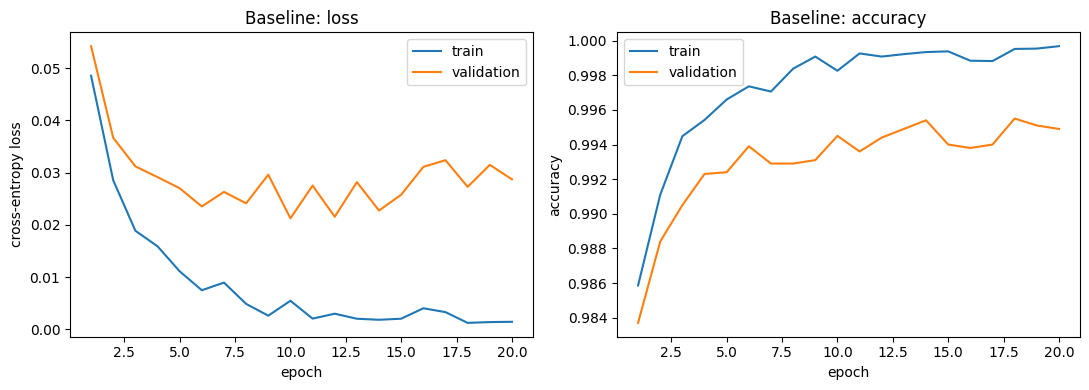

ID accuracy (mean over seeds): 99.65%


In [4]:
# ---------------- وظیفه ۱: آموزش مدل پایه ----------------
def fit_erm(tr, seed, weights=None, sample_w=None, epochs=EPOCHS, tag='ERM'):
    """آموزش استاندارد (ERM). اگر weights داده شود، خطای هر نمونه در وزنش ضرب می‌شود."""
    set_seed(seed)
    model = SimpleCNN().to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=LR)
    h, N  = new_hist(), len(tr)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(N, device=DEVICE) if sample_w is None else torch.multinomial(sample_w, N, replacement=True)
        run, nb = torch.zeros((), device=DEVICE), 0
        for i in range(0, N, BATCH):
            idx  = perm[i:i+BATCH]
            ce   = F.cross_entropy(model(tr.x[idx]), tr.y[idx], reduction='none')
            loss = ce.mean() if weights is None else (weights[idx] * ce).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach(); nb += 1
        log_epoch(h, model, (run / nb).item(), tag, ep)
    return model, h

t0 = time.time()
for s in SEEDS:
    m, h = fit_erm(S['train'], s, tag='Baseline')
    register('Baseline', s, m, h)
print(f"time: {time.time()-t0:.0f}s")

# ذخیره وزن‌ها (seed اول)
torch.save(MODELS['Baseline'][SEEDS[0]].state_dict(), "baseline_model.pth")
torch.save(MODELS['Baseline'][SEEDS[0]].state_dict(), f"{OUT}/baseline_model.pth")

# منحنی Loss و Accuracy (seed اول)
h = HIST['Baseline'][SEEDS[0]]; ep = np.arange(1, len(h['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h['train_loss'], label='train'); ax[0].plot(ep, h['val_loss'], label='validation')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('cross-entropy loss'); ax[0].set_title('Baseline: loss'); ax[0].legend()
ax[1].plot(ep, h['train_acc'], label='train'); ax[1].plot(ep, h['val_acc'], label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('accuracy'); ax[1].set_title('Baseline: accuracy'); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_baseline_training_curves.png", dpi=150); plt.show()
print("ID accuracy (mean over seeds): %.2f%%" % (100*np.mean([RES['Baseline'][s]['id'] for s in SEEDS])))
save_results()

## وظیفه ۲: ارزیابی ID/OOD (جدول ۱)

,مجموعه,ρ,دقت % (mean±std)
0,آموزش,0.9,99.96 ± 0.01
1,اعتبارسنجی,0.9,99.49 ± 0.03
2,تست ID,0.9,99.65 ± 0.06
3,تست OOD-1 (رنگ مستقل از رقم),0.1,97.61 ± 0.26
4,تست OOD-2 (رنگ همیشه مخالف),0.0,97.33 ± 0.29
5,تست ID – رنگ هم‌جهت با شکل,-,99.85 ± 0.04
6,تست ID – رنگ مخالف شکل,-,97.88 ± 0.49


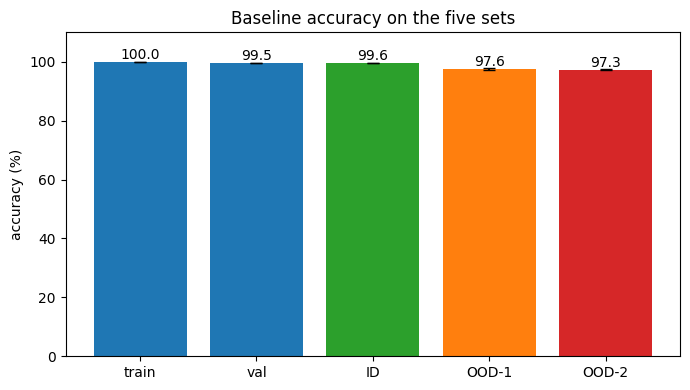

In [5]:
# ---------------- وظیفه ۲: ارزیابی ID و OOD (جدول ۱) ----------------
def agg(method, key, src=None):
    src = RES if src is None else src
    v = np.array([src[method][s][key] for s in SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

rows = []
for k in ['train', 'val', 'id', 'ood1', 'ood2']:
    m, sd = agg('Baseline', k)
    rows.append({'مجموعه': SET_INFO[k][0], 'ρ': SET_INFO[k][1], 'دقت % (mean±std)': f"{m:.2f} ± {sd:.2f}"})
for k, nm in [('id_aligned', 'تست ID – رنگ هم‌جهت با شکل'), ('id_conflict', 'تست ID – رنگ مخالف شکل')]:
    m, sd = agg('Baseline', k)
    rows.append({'مجموعه': nm, 'ρ': '-', 'دقت % (mean±std)': f"{m:.2f} ± {sd:.2f}"})
T1 = pd.DataFrame(rows); T1.to_csv(f"{OUT}/table1_baseline_eval.csv", index=False, encoding='utf-8-sig')
display(T1)

fig, ax = plt.subplots(figsize=(7, 4))
keys = ['train', 'val', 'id', 'ood1', 'ood2']
mm = [agg('Baseline', k)[0] for k in keys]; ss = [agg('Baseline', k)[1] for k in keys]
ax.bar(['train', 'val', 'ID', 'OOD-1', 'OOD-2'], mm, yerr=ss, capsize=4, color=['C0', 'C0', 'C2', 'C1', 'C3'])
for i, v in enumerate(mm): ax.text(i, v + 1, f"{v:.1f}", ha='center')
ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 110); ax.set_title('Baseline accuracy on the five sets')
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_baseline_accuracy.png", dpi=150); plt.show()

## وظیفه ۳: تشخیص نشانه

In [6]:
# ---------------- وظیفه ۳: تشخیص نشانه (نسخه ۱۰ رنگ) ----------------
def recolor(gray, c):  return gray[:, None] * PAL_T[c][:, :, None, None]            # رنگ‌آمیزی دوباره با اندیس رنگ c
def white(x):          return x.amax(1, keepdim=True).expand(-1, 3, -1, -1).clone() # حذف رنگ با حفظ شدت (رقم سفید)
# (میانگین کانال‌ها اینجا استفاده نمی‌شود: چون رنگ‌ها تعداد کانال روشن متفاوت دارند، شدت خودش رنگ را لو می‌دهد.)
def rot90(x):          return torch.rot90(x, 1, dims=(2, 3))
def occlude_top(x):
    x = x.clone(); x[:, :, :14, :] = 0; return x
def patch_shuffle(x, p=7):
    B, C_, H, W = x.shape; g = H // p
    pt  = x.unfold(2, p, p).unfold(3, p, p).reshape(B, C_, g * g, p, p).permute(0, 2, 1, 3, 4)
    prm = torch.argsort(torch.rand(B, g * g, device=x.device), dim=1)
    pt  = pt[torch.arange(B, device=x.device)[:, None], prm]
    return pt.reshape(B, g, g, C_, p, p).permute(0, 3, 1, 4, 2, 5).reshape(B, C_, H, W)

def probe(model, x, y, c_shown):
    """acc: دقت ۱۰ کلاسه | follow: درصد پیش‌بینی‌هایی که برابر رقمِ متناظر با رنگ نمایش‌داده‌شده‌اند (شانس = 10٪)."""
    p = predict(model, x)
    return {'acc': (p == y).float().mean().item(), 'follow': (p == c_shown).float().mean().item()}

SUB = torch.randperm(len(S['id']), generator=torch.Generator().manual_seed(7))[:1000].to(DEVICE)

def cue_suite(model):
    d, o = S['id'], {}
    c2 = (d.c + 1) % 10                                             # جابه‌جایی چرخشی رنگ‌ها: رنگ هر رقم ← رنگ رقم بعدی
    o['original']    = probe(model, d.x, d.y, d.c)
    o['A_swap']      = probe(model, recolor(d.gray, c2), d.y, c2)    # تست A (تعویض رنگ)
    o['B_gray_sum']  = probe(model, white(d.x), d.y, d.c)            # تست B′ (حذف رنگ با حفظ شدت)
    xs, ys, cs = d.x[SUB], d.y[SUB], d.c[SUB]
    torch.manual_seed(1234)
    o['M_orig']          = probe(model, xs, ys, cs)
    o['M_shape_rot90']   = probe(model, rot90(xs), ys, cs)
    o['M_shape_occlude'] = probe(model, occlude_top(xs), ys, cs)
    o['M_shape_shuffle'] = probe(model, patch_shuffle(xs), ys, cs)
    o['M_color_swap']    = probe(model, recolor(d.gray[SUB], (cs + 1) % 10), ys, (cs + 1) % 10)
    o['M_color_gray']    = probe(model, white(xs), ys, cs)
    return o

for s in SEEDS:
    CUE.setdefault('Baseline', {})[s] = cue_suite(MODELS['Baseline'][s])

def cagg(method, probe_name, key):
    v = np.array([CUE[method][s][probe_name][key] for s in SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

rows = []
for k, nm in [('original', 'تست ID اصلی (مرجع)'), ('A_swap', 'تست A: جابه‌جایی رنگ‌ها (c ← c+1)'), ('B_gray_sum', 'تست B′: حذف رنگ (رقم سفید)')]:
    m, sd = cagg('Baseline', k, 'acc'); f, _ = cagg('Baseline', k, 'follow')
    rows.append({'تست': nm, 'دقت %': f"{m:.2f} ± {sd:.2f}", 'نرخ پیروی از رنگ % (شانس=10)': f"{f:.1f}"})
T2 = pd.DataFrame(rows); T2.to_csv(f"{OUT}/table2_counterfactual.csv", index=False, encoding='utf-8-sig'); display(T2)

rows = []
for k, nm in [('M_orig', 'بدون تغییر (۱۰۰۰ نمونه)'), ('M_shape_rot90', 'تغییر شکل: چرخش ۹۰°'), ('M_shape_occlude', 'تغییر شکل: حذف نیمه بالایی'),
              ('M_shape_shuffle', 'تغییر شکل: بُر زدن قطعه‌ها'), ('M_color_swap', 'تغییر رنگ: جابه‌جایی'), ('M_color_gray', 'تغییر رنگ: حذف')]:
    a, sd = cagg('Baseline', k, 'acc'); f, _ = cagg('Baseline', k, 'follow')
    rows.append({'آزمون': nm, 'دقت ۱۰ کلاسه %': f"{a:.2f} ± {sd:.2f}", 'نرخ پیروی از رنگ % (شانس=10)': f"{f:.1f}"})
T2b = pd.DataFrame(rows); T2b.to_csv(f"{OUT}/table2b_misspecification.csv", index=False, encoding='utf-8-sig'); display(T2b)
save_results()

,تست,دقت %,نرخ پیروی از رنگ % (شانس=10)
0,تست ID اصلی (مرجع),99.65 ± 0.06,89.9
1,تست A: جابه‌جایی رنگ‌ها (c ← c+1),97.05 ± 0.19,2.5
2,تست B′: حذف رنگ (رقم سفید),97.43 ± 0.77,87.6


,آزمون,دقت ۱۰ کلاسه %,نرخ پیروی از رنگ % (شانس=10)
0,بدون تغییر (۱۰۰۰ نمونه),99.57 ± 0.12,89.6
1,تغییر شکل: چرخش ۹۰°,31.53 ± 1.50,32.5
2,تغییر شکل: حذف نیمه بالایی,82.33 ± 6.11,77.3
3,تغییر شکل: بُر زدن قطعه‌ها,23.57 ± 2.43,24.2
4,تغییر رنگ: جابه‌جایی,96.70 ± 0.40,2.2
5,تغییر رنگ: حذف,96.63 ± 0.78,86.6


### Saliency Map

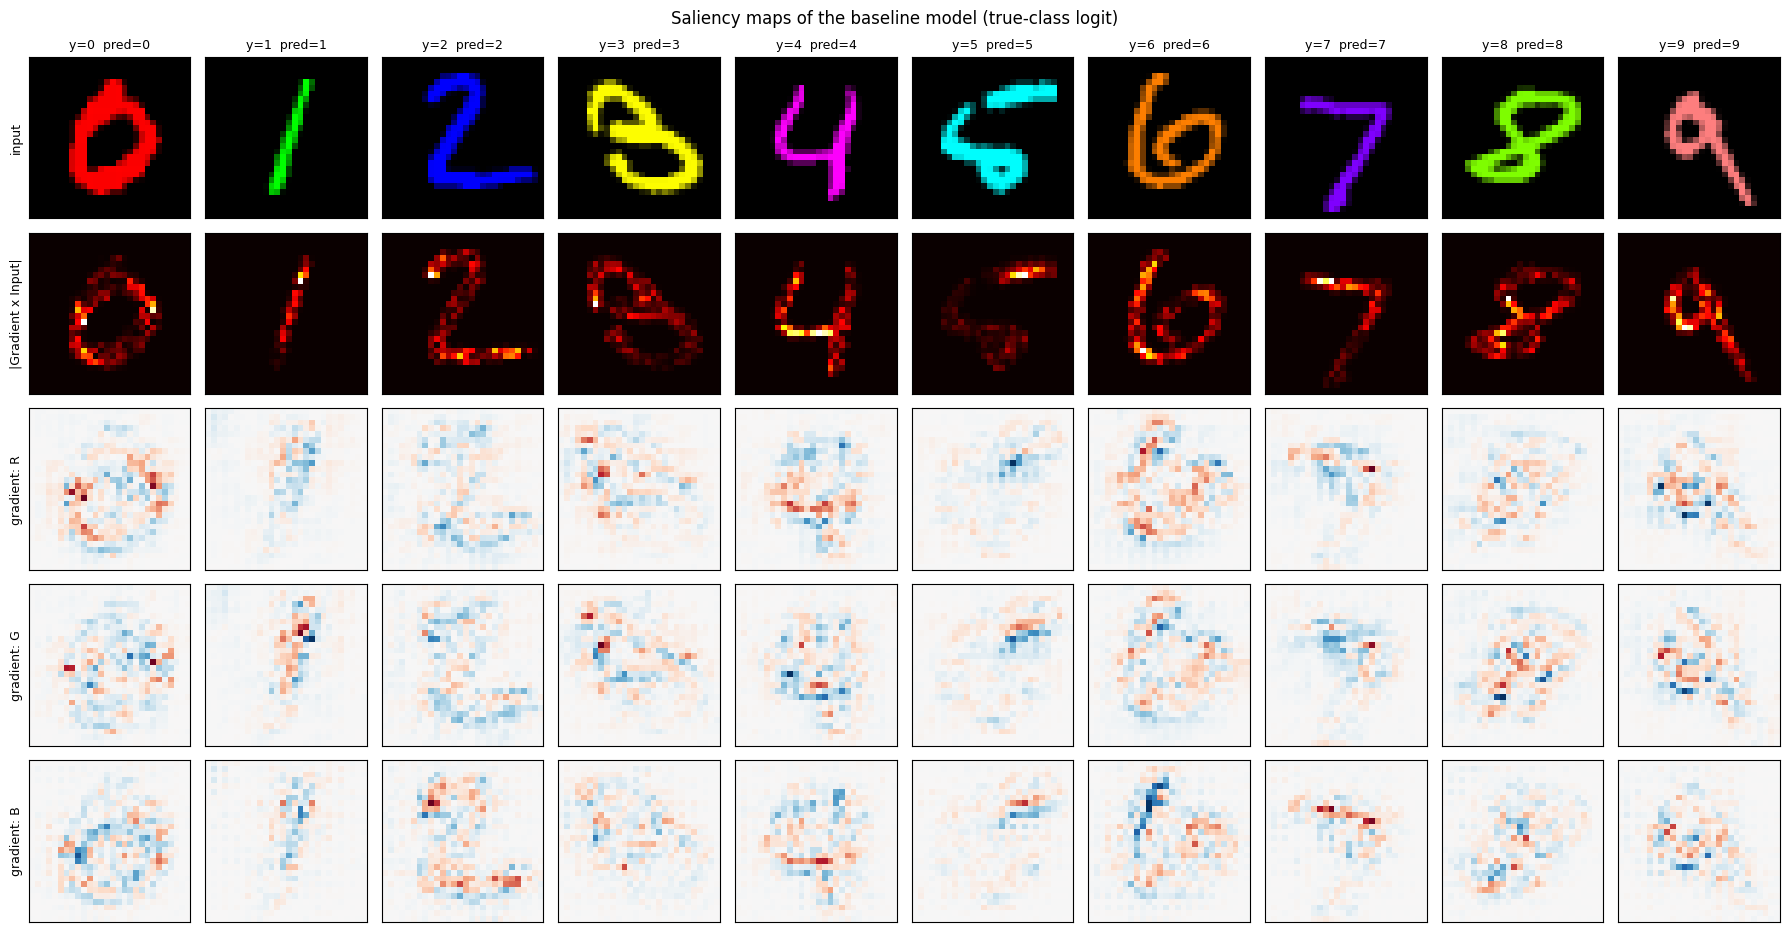

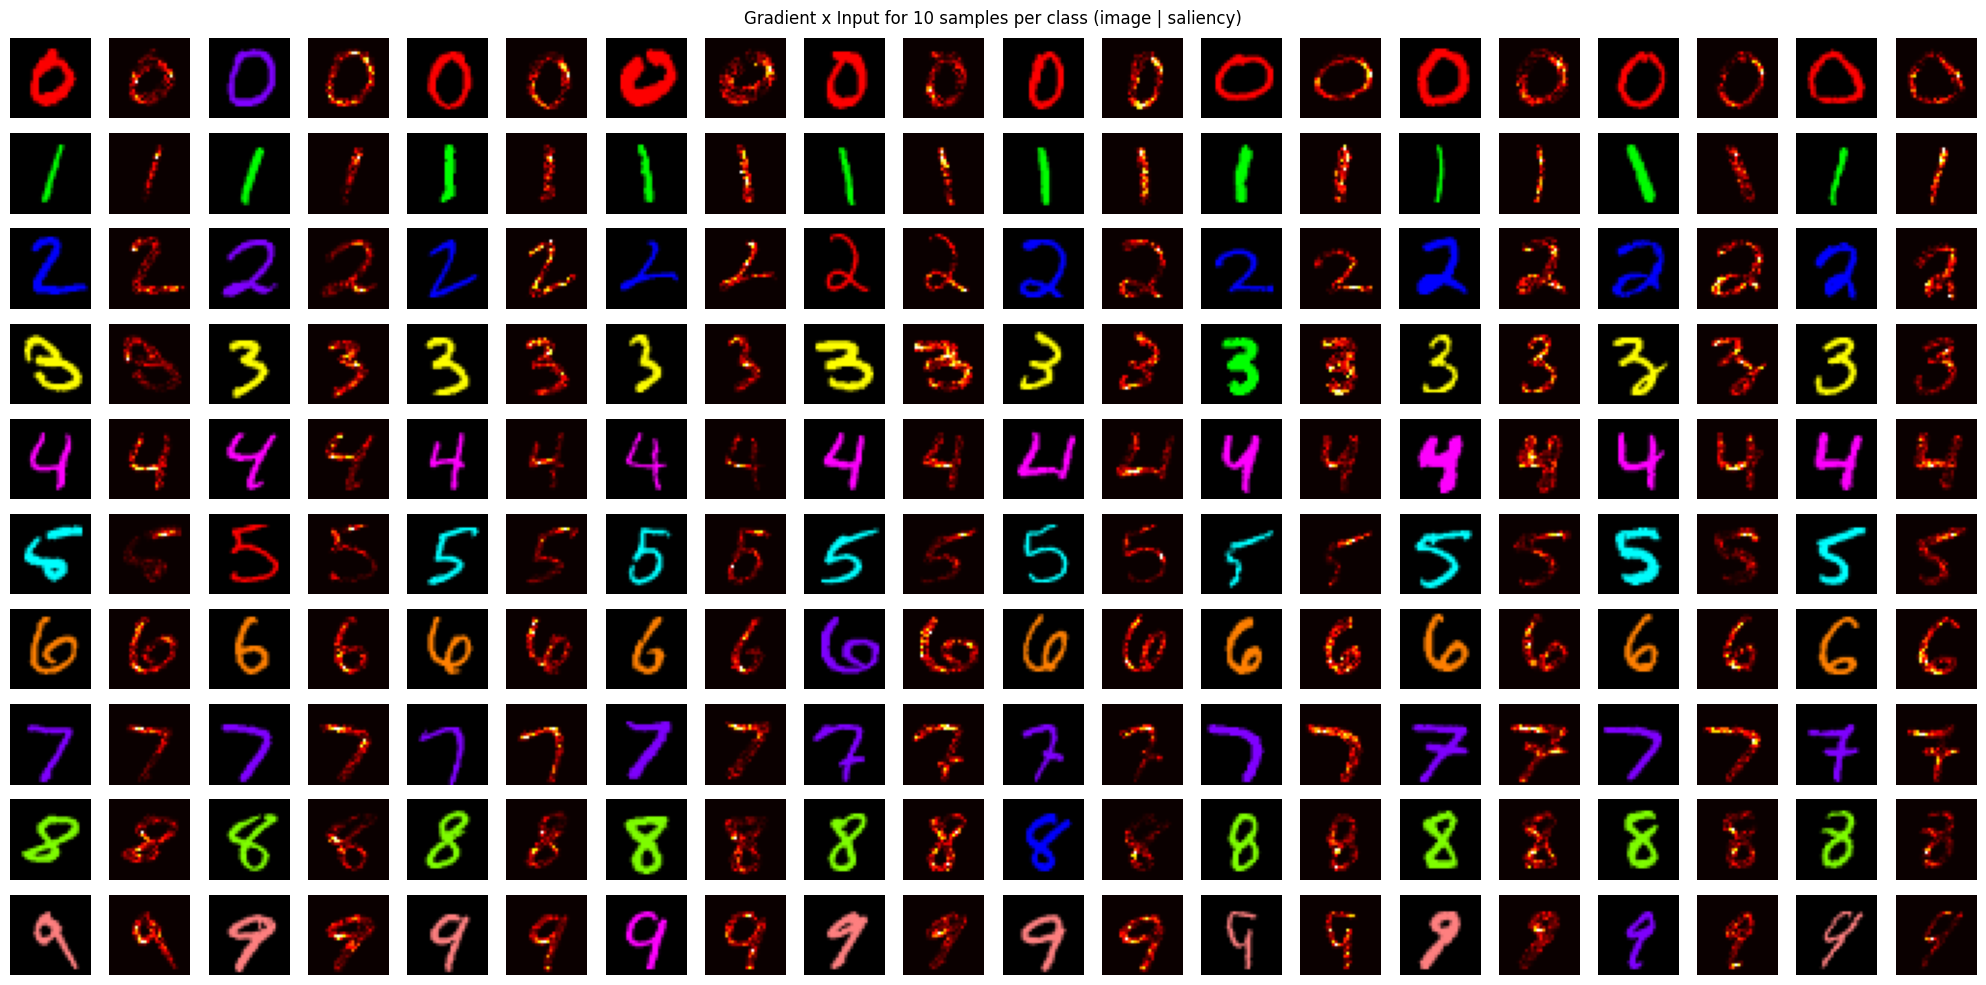

In [7]:
# Saliency Map: Gradient×Input و گرادیان خام هر سه کانال رنگ
def attributions(model, x, target):
    model.eval()
    x = x.clone().requires_grad_(True)
    grad, = torch.autograd.grad(model(x).gather(1, target[:, None]).sum(), x)
    return grad.detach(), (grad * x).detach()

base_model = MODELS['Baseline'][SEEDS[0]]
d = S['id']
idx10 = [torch.nonzero(d.y == k)[0, 0].item() for k in range(10)]
x, y = d.x[idx10], d.y[idx10]
g, gxi = attributions(base_model, x, y); pred = predict(base_model, x)
fig, axes = plt.subplots(5, 10, figsize=(18, 9.5))
for j in range(10):
    axes[0, j].imshow(x[j].permute(1, 2, 0).cpu().numpy()); axes[0, j].set_title(f"y={y[j].item()}  pred={pred[j].item()}", fontsize=9)
    axes[1, j].imshow(gxi[j].abs().sum(0).cpu().numpy(), cmap='hot')
    v = g[j].abs().max().item() + 1e-12
    for ch in range(3): axes[2 + ch, j].imshow(g[j, ch].cpu().numpy(), cmap='RdBu_r', vmin=-v, vmax=v)
    for r in range(5): axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
for r, t in enumerate(['input', '|Gradient x Input|', 'gradient: R', 'gradient: G', 'gradient: B']): axes[r, 0].set_ylabel(t, fontsize=9)
plt.suptitle("Saliency maps of the baseline model (true-class logit)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig3_saliency.png", dpi=150); plt.show()

fig, axes = plt.subplots(10, 20, figsize=(20, 10))
for k in range(10):
    ids = torch.nonzero(d.y == k)[:10, 0]
    gk, gxik = attributions(base_model, d.x[ids], d.y[ids])
    for j in range(10):
        axes[k, 2*j].imshow(d.x[ids[j]].permute(1, 2, 0).cpu().numpy()); axes[k, 2*j+1].imshow(gxik[j].abs().sum(0).cpu().numpy(), cmap='hot')
        axes[k, 2*j].axis('off'); axes[k, 2*j+1].axis('off')
plt.suptitle("Gradient x Input for 10 samples per class (image | saliency)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig3b_saliency_100samples.png", dpi=110); plt.show()

### Grad-CAM

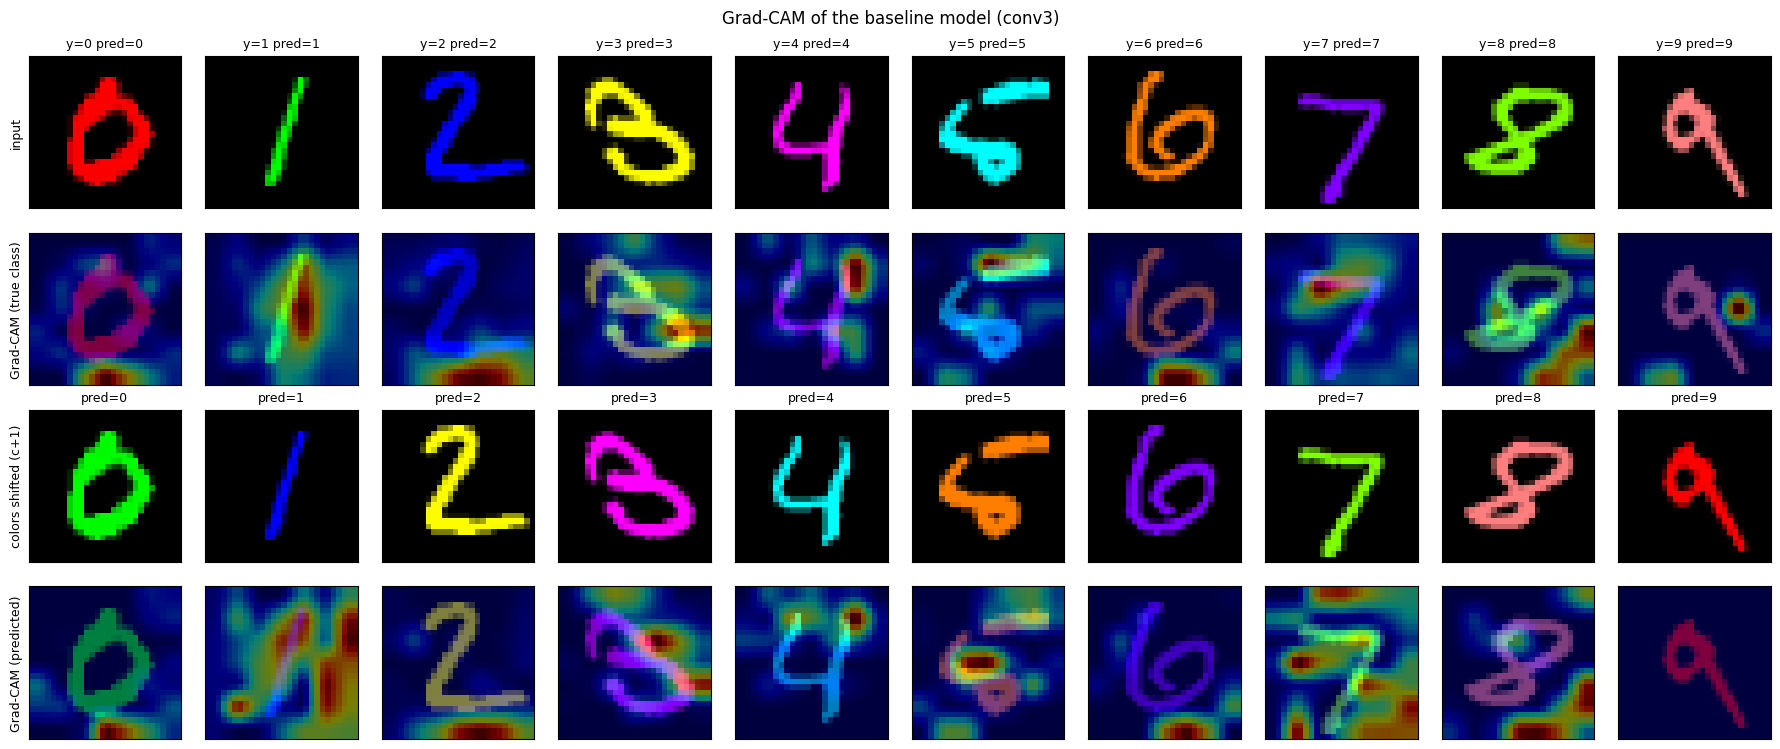

In [8]:
# ۳.۳ Grad-CAM روی آخرین لایه کانولوشن (conv3، نقشه 7×7)
def grad_cam(model, x, target=None):
    model.eval()
    f = model.features(x).detach().requires_grad_(True)
    out = model.head(f)
    pred = out.argmax(1)
    t = pred if target is None else target
    grads, = torch.autograd.grad(out.gather(1, t[:, None]).sum(), f)
    w   = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * f).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(28, 28), mode='bilinear', align_corners=False)
    cam = cam / (cam.amax(dim=(2, 3), keepdim=True) + 1e-8)
    return cam.squeeze(1).detach(), pred

x, y = d.x[idx10], d.y[idx10]
cam1, p1 = grad_cam(base_model, x, y)                 # نمونه اصلی، کلاس درست
xs = recolor(d.gray[idx10], (d.c[idx10] + 1) % 10)
cam2, p2 = grad_cam(base_model, xs, None)             # همان رقم با رنگ تعویض‌شده، کلاس پیش‌بینی‌شده

fig, axes = plt.subplots(4, 10, figsize=(18, 7.6))
for j in range(10):
    im1, im2 = x[j].permute(1, 2, 0).cpu().numpy(), xs[j].permute(1, 2, 0).cpu().numpy()
    axes[0, j].imshow(im1); axes[0, j].set_title(f"y={y[j].item()} pred={p1[j].item()}", fontsize=9)
    axes[1, j].imshow(im1); axes[1, j].imshow(cam1[j].cpu().numpy(), cmap='jet', alpha=0.5)
    axes[2, j].imshow(im2); axes[2, j].set_title(f"pred={p2[j].item()}", fontsize=9)
    axes[3, j].imshow(im2); axes[3, j].imshow(cam2[j].cpu().numpy(), cmap='jet', alpha=0.5)
    for r in range(4): axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
for r, t in enumerate(['input', 'Grad-CAM (true class)', 'colors shifted (c+1)', 'Grad-CAM (predicted)']):
    axes[r, 0].set_ylabel(t, fontsize=9)
plt.suptitle("Grad-CAM of the baseline model (conv3)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig4_gradcam.png", dpi=150); plt.show()

## وظیفه ۴: پنج روش کاهش سوگیری

In [9]:
# ---------------- وظیفه ۴: روش‌های کاهش سوگیری (هر پنج روش) ----------------
# روش ۱: Data Augmentation — ۱۰٪ نمونه بدون سوگیری (ρ=0.5) از ارقام «آموزش» ساخته و اضافه می‌شود
n_aug   = int(AUG_FRAC * len(S['train']))
aug_sel = np.random.RandomState(100).choice(len(tr_idx), n_aug, replace=False)
g_aug, y_aug = G_tr[tr_idx][aug_sel], Y_tr[tr_idx][aug_sel]
S_aug = CData(np.concatenate([G_tr[tr_idx], g_aug]),
              np.concatenate([Y_tr[tr_idx], y_aug]),
              np.concatenate([make_colors(Y_tr[tr_idx], RHO_TRAIN, 42), make_colors(y_aug, 0.1, 47)]))
print("augmented train size:", len(S_aug), "| aligned fraction: %.3f" % S_aug.aligned.float().mean().item())

# روش ۲: Reweighting — w_i = 1 / P(color=c_i | shape=s_i)، با برآورد تجربی P از داده آموزش
def reweight_weights(tr):
    w = torch.zeros(len(tr), device=DEVICE)
    for yy in range(10):
        for cc in range(10):
            m = (tr.y == yy) & (tr.c == cc)
            if m.any():
                w[m] = (tr.y == yy).sum().item() / m.sum().item()          # = 1 / P(color | digit)
    return w / w.mean()
W_RW = reweight_weights(S['train'])
print("reweighting: weight(aligned)=%.3f  weight(conflicting)=%.3f" %
      (W_RW[S['train'].aligned][0].item(), W_RW[~S['train'].aligned][0].item()))

NG = 20   # گروه‌ها: (رقم × هم‌جهت/مخالف)
# روش ۳: Group DRO — کمینه‌سازی بدترین خطای گروهی با وزن‌های q_g (به‌روزرسانی نمایی)
def fit_group_dro(tr, seed, eta=DRO_ETA, epochs=EPOCHS):
    set_seed(seed)
    model = SimpleCNN().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    q = torch.ones(NG, device=DEVICE) / NG
    h, N = new_hist(), len(tr)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(N, device=DEVICE)
        run, nb = torch.zeros((), device=DEVICE), 0
        for i in range(0, N, BATCH):
            idx = perm[i:i+BATCH]
            ce  = F.cross_entropy(model(tr.x[idx]), tr.y[idx], reduction='none')
            oh  = F.one_hot(tr.g[idx], NG).float()                    # (B,4)
            cnt = oh.sum(0)
            gl  = (oh * ce[:, None]).sum(0) / cnt.clamp_min(1)       # میانگین خطا در هر گروه (گروه غایب → 0)
            q   = q * torch.exp(eta * gl.detach())                   # گروه غایب: exp(0)=1
            q   = q / q.sum()
            loss = (q * gl).sum()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach(); nb += 1
        log_epoch(h, model, (run / nb).item(), 'GroupDRO', ep)
    h['q_final'] = q.tolist()
    return model, h

# روش ۴: Learning from Failure — مدل سوگیرانه با GCE + مدل نهایی با وزن W = CE_B / (CE_B + CE_D)
def fit_lff(tr, seed, q=GCE_Q, alpha=EMA_ALPHA, epochs=EPOCHS):
    set_seed(seed)
    mb, md = SimpleCNN().to(DEVICE), SimpleCNN().to(DEVICE)
    opt = torch.optim.Adam(list(mb.parameters()) + list(md.parameters()), lr=LR)
    N = len(tr); h = new_hist()
    ema_b, ema_d = torch.zeros(N, device=DEVICE), torch.zeros(N, device=DEVICE)
    for ep in range(epochs):
        mb.train(); md.train(); perm = torch.randperm(N, device=DEVICE)
        run, nb = torch.zeros((), device=DEVICE), 0
        for i in range(0, N, BATCH):
            idx = perm[i:i+BATCH]; x, y = tr.x[idx], tr.y[idx]
            lb, ld = mb(x), md(x)
            ce_b = F.cross_entropy(lb, y, reduction='none'); ce_d = F.cross_entropy(ld, y, reduction='none')
            ema_b[idx] = alpha * ema_b[idx] + (1 - alpha) * ce_b.detach()       # EMA خطای هر نمونه
            ema_d[idx] = alpha * ema_d[idx] + (1 - alpha) * ce_d.detach()
            mx_b = torch.zeros(10, device=DEVICE).scatter_reduce(0, tr.y, ema_b, reduce='amax', include_self=True)
            mx_d = torch.zeros(10, device=DEVICE).scatter_reduce(0, tr.y, ema_d, reduce='amax', include_self=True)
            nb_  = ema_b[idx] / mx_b[y].clamp_min(1e-8)                          # نرمال‌سازی بر اساس بیشینه کلاس
            nd_  = ema_d[idx] / mx_d[y].clamp_min(1e-8)
            w    = nb_ / (nb_ + nd_ + 1e-8)                                      # نمونه‌های «سخت برای مدل سوگیرانه» وزن بیشتر
            p_y  = F.softmax(lb, 1).gather(1, y[:, None]).squeeze(1).clamp_min(1e-8)
            gce  = (1 - p_y ** q) / q                                            # Generalized CE
            loss = gce.mean() + (w.detach() * ce_d).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach(); nb += 1
        log_epoch(h, md, (run / nb).item(), 'LfF', ep)                           # مدل نهایی = مدل بی‌سوگیری md
    return md, h

# روش ۵: IRM — دو محیط با ρ=0.9 و ρ=0.5 (نیمی از ارقام آموزش در هر محیط) و جریمه IRMv1
n_half = len(tr_idx) // 2
ENVS = [make_cmnist(G_tr[tr_idx[:n_half]], Y_tr[tr_idx[:n_half]], RHO_TRAIN, 48),
        make_cmnist(G_tr[tr_idx[n_half:]], Y_tr[tr_idx[n_half:]], 0.5, 49)]

def fit_irm(envs, seed, lam=IRM_LAMBDA, anneal=IRM_ANNEAL, epochs=EPOCHS):
    set_seed(seed)
    model = SimpleCNN().to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    h = new_hist(); n_steps = math.ceil(min(len(e) for e in envs) / BATCH)
    for ep in range(epochs):
        model.train(); perms = [torch.randperm(len(e), device=DEVICE) for e in envs]
        run = torch.zeros((), device=DEVICE)
        for s in range(n_steps):
            risks, pens = [], []
            for e, pm in zip(envs, perms):
                idx   = pm[s*BATCH:(s+1)*BATCH]
                scale = torch.tensor(1.0, device=DEVICE, requires_grad=True)       # w=1 در IRMv1
                risk  = F.cross_entropy(model(e.x[idx]) * scale, e.y[idx])
                gw,   = torch.autograd.grad(risk, [scale], create_graph=True)
                risks.append(risk); pens.append(gw ** 2)
            erm, pen = torch.stack(risks).mean(), torch.stack(pens).mean()
            wt   = lam if ep >= anneal else 1.0
            loss = erm + wt * pen
            if wt > 1.0: loss = loss / wt                                           # حفظ مقیاس گرادیان (مثل کد IRM)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            run += loss.detach()
        log_epoch(h, model, (run / n_steps).item(), 'IRM', ep)
    return model, h

METHODS = {
    'M1_Augmentation': lambda s: fit_erm(S_aug, s, tag='Aug'),
    'M2_Reweighting':  lambda s: fit_erm(S['train'], s, sample_w=W_RW, tag='Reweight'),
    'M3_GroupDRO':     lambda s: fit_group_dro(S['train'], s),
    'M4_LfF':          lambda s: fit_lff(S['train'], s),
    'M5_IRM':          lambda s: fit_irm(ENVS, s),
}

augmented train size: 55000 | aligned fraction: 0.828
reweighting: weight(aligned)=0.111  weight(conflicting)=9.578


In [10]:
# ---------------- اجرای همه روش‌ها روی همه seedها ----------------
for name, fn in METHODS.items():
    t0 = time.time()
    for s in SEEDS:
        m, h = fn(s)
        register(name, s, m, h)
        CUE.setdefault(name, {})[s] = cue_suite(m)
    print(f"##### {name} done in {time.time()-t0:.0f}s\n")
    torch.save({s: MODELS[name][s].state_dict() for s in SEEDS}, f"{OUT}/{name}_weights.pth")
    save_results()
CUE['Baseline'] = {s: cue_suite(MODELS['Baseline'][s]) for s in SEEDS}
save_results()

  [Aug] epoch  1  obj=0.2667  train_acc=0.9860  val_acc=0.9836  ood1=0.9310  ood2=0.9275
  [Aug] epoch  5  obj=0.0247  train_acc=0.9965  val_acc=0.9925  ood1=0.9786  ood2=0.9753
  [Aug] epoch 10  obj=0.0124  train_acc=0.9989  val_acc=0.9950  ood1=0.9797  ood2=0.9779
  [Aug] epoch 15  obj=0.0104  train_acc=0.9993  val_acc=0.9949  ood1=0.9846  ood2=0.9825
  [Aug] epoch 20  obj=0.0080  train_acc=0.9994  val_acc=0.9960  ood1=0.9825  ood2=0.9798
==> M1_Augmentation seed=0: ID=0.9956 OOD1=0.9825 OOD2=0.9798
  [Aug] epoch  1  obj=0.2604  train_acc=0.9884  val_acc=0.9879  ood1=0.9438  ood2=0.9386
  [Aug] epoch  5  obj=0.0267  train_acc=0.9972  val_acc=0.9950  ood1=0.9800  ood2=0.9768
  [Aug] epoch 10  obj=0.0151  train_acc=0.9978  val_acc=0.9938  ood1=0.9797  ood2=0.9769
  [Aug] epoch 15  obj=0.0092  train_acc=0.9994  val_acc=0.9944  ood1=0.9825  ood2=0.9795
  [Aug] epoch 20  obj=0.0069  train_acc=0.9990  val_acc=0.9926  ood1=0.9740  ood2=0.9713
==> M1_Augmentation seed=1: ID=0.9947 OOD1=0.974

### جدول ۳ و ۴ و نمودارها

,روش,دقت ID %,دقت OOD-1 %,دقت OOD-2 %,اختلاف ID−OOD1,اختلاف ID−OOD2
0,Baseline,99.65 ± 0.06,97.61 ± 0.26,97.33 ± 0.29,2.04 ± 0.22,2.32 ± 0.27
1,M1_Augmentation,99.54 ± 0.07,97.98 ± 0.50,97.75 ± 0.55,1.56 ± 0.44,1.79 ± 0.48
2,M2_Reweighting,99.23 ± 0.10,98.61 ± 0.23,98.54 ± 0.29,0.62 ± 0.19,0.69 ± 0.24
3,M3_GroupDRO,99.55 ± 0.13,98.06 ± 0.46,97.70 ± 0.27,1.49 ± 0.34,1.85 ± 0.16
4,M4_LfF,98.91 ± 0.48,97.34 ± 0.94,97.16 ± 1.03,1.57 ± 0.47,1.75 ± 0.56
5,M5_IRM,99.01 ± 0.21,97.22 ± 0.54,97.13 ± 0.46,1.79 ± 0.65,1.88 ± 0.57


,روش,دقت پس از تعویض رنگ %,دقت Grayscale (حفظ شدت) %,نرخ پیروی از رنگ پس از بُر زدن شکل %
0,Baseline,97.1,97.4,24.2
1,M1_Augmentation,97.3,98.2,20.7
2,M2_Reweighting,98.5,98.7,16.9
3,M3_GroupDRO,97.3,98.0,23.3
4,M4_LfF,97.3,96.6,16.1
5,M5_IRM,96.6,97.5,21.0


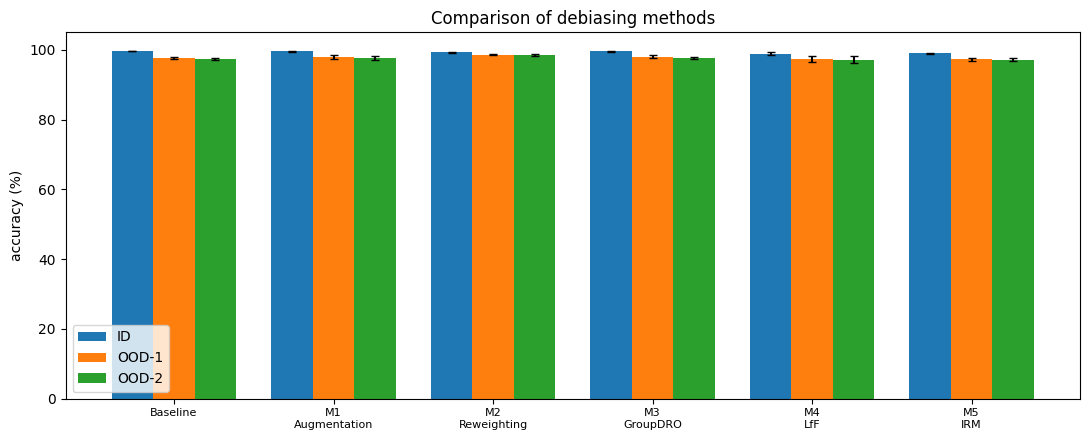

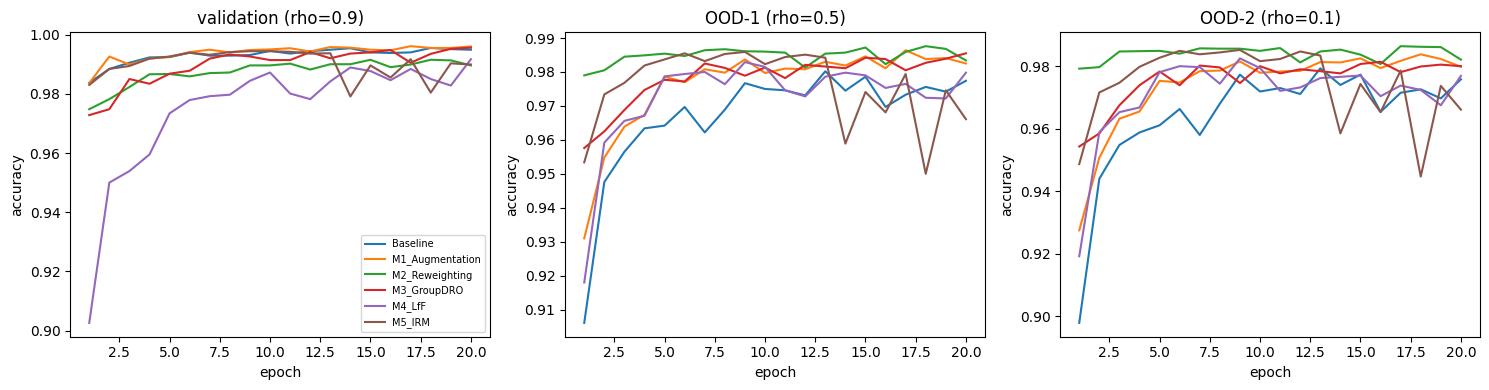

In [11]:
# ---------------- جدول ۳: مقایسه روش‌ها ----------------
ORDER = ['Baseline'] + list(METHODS.keys())
def gap_stat(method, ood):
    v = np.array([RES[method][s]['id'] - RES[method][s][ood] for s in SEEDS]) * 100
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)

rows = []
for mth in ORDER:
    r = {'روش': mth}
    for k, nm in [('id', 'ID'), ('ood1', 'OOD-1'), ('ood2', 'OOD-2')]:
        m, sd = agg(mth, k); r[f'دقت {nm} %'] = f"{m:.2f} ± {sd:.2f}"
    for ood, nm in [('ood1', 'ID−OOD1'), ('ood2', 'ID−OOD2')]:
        m, sd = gap_stat(mth, ood); r[f'اختلاف {nm}'] = f"{m:.2f} ± {sd:.2f}"
    rows.append(r)
T3 = pd.DataFrame(rows); T3.to_csv(f"{OUT}/table3_methods.csv", index=False, encoding='utf-8-sig'); display(T3)

# جدول ۴ (تکمیلی): پروفایل «تکیه بر رنگ» برای همه روش‌ها
rows = []
for mth in ORDER:
    a, _ = cagg(mth, 'A_swap', 'acc'); b, _ = cagg(mth, 'B_gray_sum', 'acc'); f, _ = cagg(mth, 'M_shape_shuffle', 'follow')
    rows.append({'روش': mth, 'دقت پس از تعویض رنگ %': f"{a:.1f}", 'دقت Grayscale (حفظ شدت) %': f"{b:.1f}",
                 'نرخ پیروی از رنگ پس از بُر زدن شکل %': f"{f:.1f}"})
T4 = pd.DataFrame(rows); T4.to_csv(f"{OUT}/table4_cue_profile.csv", index=False, encoding='utf-8-sig'); display(T4)

# نمودار مقایسه‌ای
fig, ax = plt.subplots(figsize=(11, 4.5)); wd = 0.26; xs_ = np.arange(len(ORDER))
for j, (k, nm) in enumerate([('id', 'ID'), ('ood1', 'OOD-1'), ('ood2', 'OOD-2')]):
    ax.bar(xs_ + (j - 1) * wd, [agg(m_, k)[0] for m_ in ORDER], wd, yerr=[agg(m_, k)[1] for m_ in ORDER], capsize=3, label=nm)
ax.set_xticks(xs_); ax.set_xticklabels([m_.replace('_', '\n') for m_ in ORDER], fontsize=8)
ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 105); ax.legend(); ax.set_title('Comparison of debiasing methods')
plt.tight_layout(); plt.savefig(f"{OUT}/fig5_methods_comparison.png", dpi=150); plt.show()

# پویایی یادگیری (seed اول)
fig, ax = plt.subplots(1, 3, figsize=(15, 4)); s0 = SEEDS[0]
for j, (k, nm) in enumerate([('val_acc', f'validation (rho={RHO_TRAIN})'), ('ood1_acc', 'OOD-1 (rho=0.5)'), ('ood2_acc', 'OOD-2 (rho=0.1)')]):
    for mth in ORDER: ax[j].plot(range(1, EPOCHS + 1), HIST[mth][s0][k], label=mth)
    ax[j].set_title(nm); ax[j].set_xlabel('epoch'); ax[j].set_ylabel('accuracy')
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/fig6_training_dynamics.png", dpi=150); plt.show()
save_results()

In [12]:
import shutil
shutil.make_archive('project_10colors_results', 'zip', OUT)
try:
    from google.colab import files
    files.download('project_10colors_results.zip')
except Exception:
    print('zip saved: project_10colors_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>